# EduBot Analytics: regressão linear do TP3

O objetivo deste notebook é usar uma regressão linear múltipla para prever uma
variável numérica derivada do texto. Isso não muda o objetivo final do projeto,
que continua sendo classificar a intenção de uma mensagem.

Escolhi `n_chars` como alvo. As variáveis explicativas são o número de palavras,
as flags linguísticas do Bitext e a categoria adaptada para o EduBot. O modelo
serve para praticar o pipeline de regressão, as métricas e a análise de resíduos.
Ele não será usado como classificador.

## Como reproduzir

1. Instale as dependências com `pip install -r requirements.txt`.
2. Execute este notebook por completo.

O arquivo `data/edubot_dataset_tratado.csv` já está versionado no repositório.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

BASE_DIR = Path.cwd()
if BASE_DIR.name != "eda":
    BASE_DIR = BASE_DIR / "eda"

FIGURES_DIR = BASE_DIR / "figures"
FIGURES_DIR.mkdir(exist_ok=True)

dados = pd.read_csv(BASE_DIR / "data" / "edubot_dataset_tratado.csv")
sns.set_theme(style="whitegrid")

print(f"Dataset: {dados.shape[0]:,} linhas e {dados.shape[1]} colunas")
dados[["instruction", "n_palavras", "n_chars", "categoria_edubot"]].head()

Dataset: 21,006 linhas e 17 colunas


,instruction,n_palavras,n_chars,categoria_edubot
0,question about cancelling order {{Order Number}},6,48,ACADEMICO
1,i have a question about cancelling oorder {{Or...,9,58,ACADEMICO
2,i need help cancelling puchase {{Order Number}},7,47,ACADEMICO
3,I need to cancel purchase {{Order Number}},7,42,ACADEMICO
4,"I cannot afford this order, cancel purchase {{...",9,60,ACADEMICO


## 1. Alvo e variáveis explicativas

O alvo é `n_chars`, que representa o comprimento da mensagem em caracteres.
Usei mais de uma variável explicativa, então esta é uma regressão múltipla.

`n_palavras` traz a informação de comprimento mais direta. As flags indicam
marcas como typo, abreviação, negação e linguagem coloquial. A categoria é
categórica e será transformada com one-hot encoding dentro do pipeline.

In [2]:
variaveis_numericas = [
    "n_palavras",
    "tem_ofensa",
    "tem_typo",
    "tem_coloquial",
    "tem_polidez",
    "tem_negacao",
    "modo_keyword",
    "tem_abreviacao",
]
variaveis_categoricas = ["categoria_edubot"]

X = dados[variaveis_numericas + variaveis_categoricas]
y = dados["n_chars"]

display(y.describe().round(2).to_frame("n_chars"))
display(dados[variaveis_categoricas].value_counts().to_frame("n"))

,n_chars
count,21006.00
mean,46.91
std,11.26
min,6.00
25%,39.00
50%,48.00
75%,55.00
max,92.00


,n
categoria_edubot,
FINANCEIRO,6450
ACADEMICO,6009
SUPORTE,2998
CADASTRO,2557
FEEDBACK,1997
ACESSO,995


## 2. Separação e pipeline

Separei 80% dos registros para treino e 20% para teste. O
`ColumnTransformer` mantém as variáveis numéricas e aplica one-hot encoding à
categoria. O `drop="first"` evita criar uma coluna redundante para cada
categoria.

Todo o pré-processamento fica dentro do mesmo pipeline do `LinearRegression`.
Assim, o ajuste do encoder acontece apenas no conjunto de treino.

In [3]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
)

preprocessamento = ColumnTransformer(
    transformers=[
        ("numericas", "passthrough", variaveis_numericas),
        (
            "categorias",
            OneHotEncoder(drop="first", handle_unknown="ignore"),
            variaveis_categoricas,
        ),
    ]
)

modelo = Pipeline(
    steps=[
        ("preprocessamento", preprocessamento),
        ("regressao", LinearRegression()),
    ]
)

modelo.fit(X_treino, y_treino)
previsoes = modelo.predict(X_teste)
residuos = y_teste - previsoes

print(f"Treino: {len(X_treino):,} registros")
print(f"Teste: {len(X_teste):,} registros")

Treino: 16,804 registros
Teste: 4,202 registros


## 3. Métricas

O R² mostra quanto da variação do alvo é explicada pelo modelo no conjunto de
teste. O RMSE fica na mesma unidade do alvo, então pode ser lido como um erro
típico em caracteres.

In [4]:
r2 = r2_score(y_teste, previsoes)
rmse = np.sqrt(mean_squared_error(y_teste, previsoes))

metricas = pd.DataFrame(
    {
        "metrica": ["R²", "RMSE"],
        "resultado": [r2, rmse],
    }
)
display(metricas.round(3))

print(f"R² = {r2:.3f}")
print(f"RMSE = {rmse:.3f} caracteres")
print(f"Média dos resíduos = {residuos.mean():.3f}")

,metrica,resultado
0,R²,0.690
1,RMSE,6.243


R² = 0.690
RMSE = 6.243 caracteres
Média dos resíduos = 0.097


O modelo explica uma parte importante da variação de `n_chars`, principalmente
porque mensagens com mais palavras tendem a ter mais caracteres. Mesmo assim,
um RMSE de cerca de seis caracteres mostra que o comprimento não é determinado
apenas pela quantidade de palavras. O tamanho das palavras e a forma de escrita
também variam.

## 4. Residual plot

O gráfico abaixo compara os valores previstos com os resíduos. Em um ajuste
linear ideal, os pontos ficariam espalhados de forma aleatória ao redor de zero,
sem curvas nem mudança clara de amplitude.

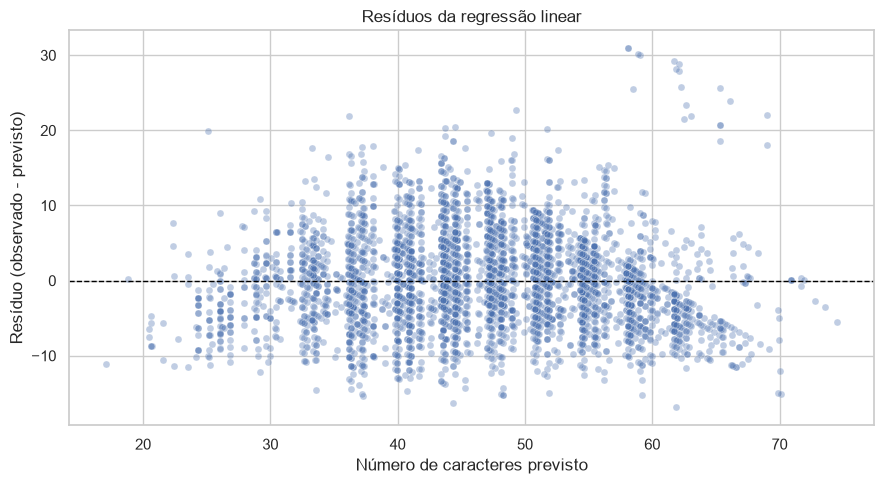

In [5]:
plt.figure(figsize=(9, 5))
sns.scatterplot(x=previsoes, y=residuos, alpha=0.35, s=25)
plt.axhline(0, color="black", linestyle="--", linewidth=1)
plt.title("Resíduos da regressão linear")
plt.xlabel("Número de caracteres previsto")
plt.ylabel("Resíduo (observado - previsto)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig10_residuos_regressao.png", dpi=150)
plt.show()

Os resíduos ficam em torno de zero, mas a dispersão não é perfeitamente
uniforme. Também aparecem faixas diagonais porque `n_chars` é inteiro e
`n_palavras` assume poucos valores. Isso limita a hipótese de variância constante.

## 5. Q-Q plot

O Q-Q plot compara os resíduos com uma distribuição normal. Pontos próximos da
reta indicam maior compatibilidade com a normalidade. Desvios nas pontas mostram
que os erros extremos não seguem bem essa hipótese.

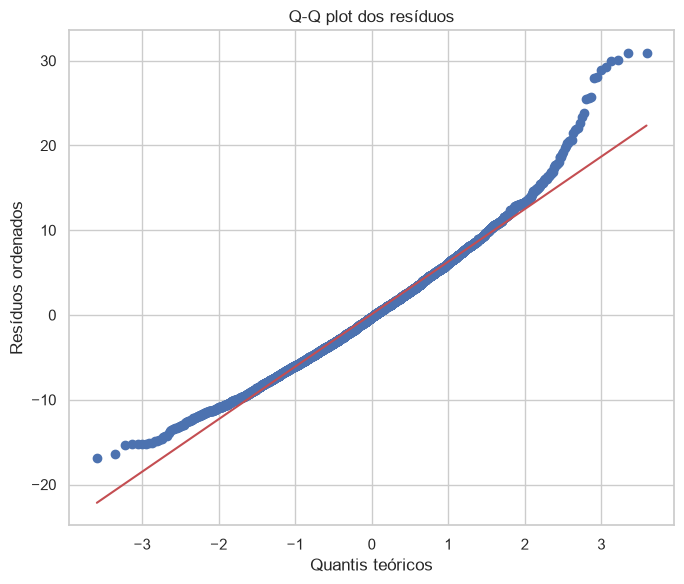

In [6]:
plt.figure(figsize=(7, 6))
stats.probplot(residuos, dist="norm", plot=plt)
plt.title("Q-Q plot dos resíduos")
plt.xlabel("Quantis teóricos")
plt.ylabel("Resíduos ordenados")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig11_qqplot_residuos.png", dpi=150)
plt.show()

O centro fica razoavelmente perto da reta, mas as caudas se afastam. Portanto,
os resíduos não são perfeitamente normais. Com mais de quatro mil observações
no teste, as métricas ainda são úteis para descrever o ajuste, mas as hipóteses
da regressão não devem ser tratadas como plenamente atendidas.

## 6. Distribuição das intenções

A próxima etapa do EduBot não vai prever caracteres. Ela vai receber uma
mensagem e devolver uma das 23 intenções em `intent_edubot`. A distribuição
abaixo ajuda a preparar essa tarefa de classificação.

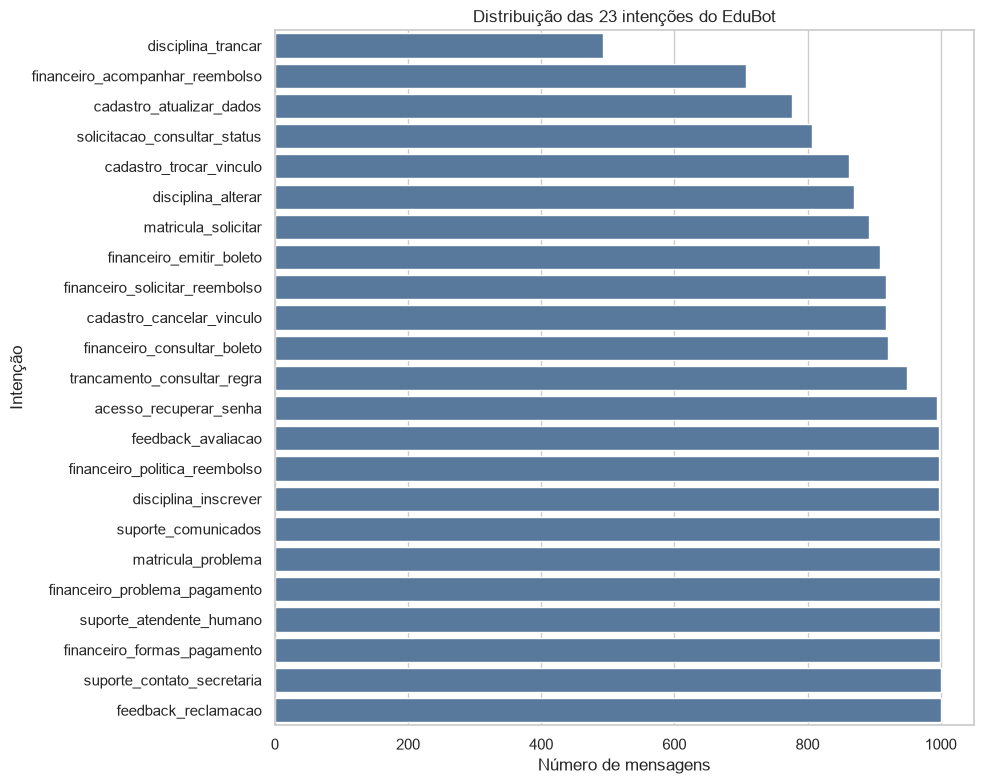

,intencao,n,pct
22,feedback_reclamacao,1000,4.76
21,suporte_contato_secretaria,1000,4.76
20,financeiro_formas_pagamento,999,4.76
19,suporte_atendente_humano,999,4.76
17,matricula_problema,999,4.76
16,suporte_comunicados,999,4.76
18,financeiro_problema_pagamento,999,4.76
15,disciplina_inscrever,998,4.75
14,financeiro_politica_reembolso,997,4.75
13,feedback_avaliacao,997,4.75


In [7]:
distribuicao_intencoes = (
    dados["intent_edubot"]
    .value_counts()
    .sort_values()
    .rename_axis("intencao")
    .reset_index(name="n")
)
distribuicao_intencoes["pct"] = (
    distribuicao_intencoes["n"] / len(dados) * 100
).round(2)

plt.figure(figsize=(10, 8))
sns.barplot(
    data=distribuicao_intencoes,
    x="n",
    y="intencao",
    color="#4C78A8",
)
plt.title("Distribuição das 23 intenções do EduBot")
plt.xlabel("Número de mensagens")
plt.ylabel("Intenção")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig12_distribuicao_intencoes_tp3.png", dpi=150)
plt.show()

display(distribuicao_intencoes.sort_values("n", ascending=False))

## 7. Limitações e próximos passos

- O alvo `n_chars` foi escolhido para praticar regressão. Ele não representa a
  intenção da pessoa nem a qualidade de uma resposta.
- A relação entre palavras e caracteres é esperada e parcialmente mecânica.
  Por isso, um R² razoável não significa que o modelo entendeu a mensagem.
- Os resíduos não apresentam variância perfeitamente constante e se afastam da
  normalidade nas caudas.
- As flags e categorias vêm do Bitext, um dataset sintético, em inglês e no
  domínio de e-commerce. O resultado não pode ser generalizado diretamente
  para mensagens acadêmicas em português.
- Intenções são classes nominais, sem ordem numérica. Uma regressão linear pode
  produzir qualquer valor contínuo e não resolve esse problema.

No T2, o baseline será `TF-IDF + regressão logística`, com comparação posterior
com SVM linear. A avaliação deve usar Macro-F1, precision, recall e matriz de
confusão em conjuntos separados de treino, validação e teste.